# SL执行脱节：固定24场审计

保持状态机规则，研究22轮SL的47次POST。识别到MATCHED平均8.071秒；撤换平均2.679秒。触发中点基准到实际配对PnL差额4.879675 USDC，不是可回收收益预测。

## 方法

统一monotonic时钟；历史触发用同次observe当前点锚定。配对篮子数量固定为实际匹配数量，不含额外尾仓结算。窄证明提前可见不是新订单成交回放。

In [1]:
import json,hashlib
from pathlib import Path
from decimal import Decimal as D
OUT=Path('/home/ubuntu/poly-maker/docs/development/reviews/20261019_repair_sl_execution_24')
s=json.loads((OUT/'summary.json').read_text())
for src in json.loads((OUT/'source_manifest.json').read_text()):
    assert hashlib.sha256(Path(src['source']).read_bytes()).hexdigest()==src['sha256']
    assert hashlib.sha256(Path(src['cache_snapshots']).read_bytes()).hexdigest()==src['cache_snapshots_sha256']
eps=s['episodes']; ws=s['windows']; gaps=s['gaps']
assert (len(eps),len(ws),len(gaps))==(22,47,25)
assert all(abs(sum(e['time_phases'].values())-e['signal_to_first_match_sec'])<1e-6 for e in eps)
assert all(w['guard_price_equals_ask_minus_tick'] for w in ws)
assert all(abs(float(w['post_yes_mid'])-w['raw_asof_post_yes_mid'])<1e-8 for w in ws)
print('Source hashes, 22 timing bridges and 47 final-price/path checks passed.')

Source hashes, 22 timing bridges and 47 final-price/path checks passed.


In [2]:
from IPython.display import display,Markdown,Image
table='|Market/episode|Trigger|Detected|POST|MATCHED|First quote target|Actual paired PnL|\n|---|---:|---:|---:|---:|---:|---:|\n'
for e in eps:
    table+=f"|{e['market']}/{e['opening_window'].split(':')[-1]}|{e['signal']:.3f}|{e['detected']:.3f}|{e['first_post']:.3f}|{e['first_match']:.3f}|{e['benchmarks']['first_post_quote_pair_target']}|{e['benchmarks']['actual_pair_pnl']}|\n"
display(Markdown(table))

|Market/episode|Trigger|Detected|POST|MATCHED|First quote target|Actual paired PnL|
|---|---:|---:|---:|---:|---:|---:|
|12:20/w2|41.496|41.499|44.259|47.411|0.02706656|0.02706656000|
|12:25/w2|45.293|45.293|47.646|61.621|-0.200000|-0.200000|
|12:25/w13|110.458|110.464|113.552|114.661|-1.000000|-1.000000|
|12:35/w5|49.927|53.369|53.396|54.299|-0.200000|-0.2000000|
|12:35/w9|76.935|77.406|77.425|84.457|-0.500000|-0.700000|
|12:45/w4|50.890|50.891|54.164|61.447|-0.050000|-1.100000|
|12:55/w22|130.933|130.937|133.321|136.723|0.100000|0.100000|
|13:05/w10|64.536|72.515|72.534|87.016|-0.950000|-1.950000|
|13:10/w3|60.899|60.924|60.951|76.999|-1.000000|-1.200000|
|13:15/w6|62.050|62.057|62.160|67.976|-1.100000|-1.350000|
|14:45/w14|77.371|83.115|83.129|90.999|-0.500000|-0.450000|
|14:45/w18|122.935|122.935|123.025|126.222|-0.350000|-0.350000|
|14:50/w1|38.606|38.610|38.623|49.277|0.20045613000|0.1145461700000000000000000000|
|14:55/w6|58.889|58.892|58.905|59.822|-0.250000|-0.250000|
|14:55/w9|105.065|105.069|105.086|109.270|-0.400000|-0.400000|
|15:05/w4|44.679|44.683|44.738|50.922|-0.150000|-0.300000|
|15:05/w10|104.746|104.749|104.765|108.575|-0.550000|-0.550000|
|15:10/w10|72.357|72.362|75.439|91.383|-0.050000|-0.750000|
|15:15/w10|86.122|89.719|89.739|100.622|-0.700000|0.400000|
|15:25/w2|47.963|47.969|47.982|49.223|-0.350000|-0.350000|
|15:25/w9|114.024|114.027|117.910|130.427|-0.100000|-0.500000|
|15:30/w9|100.628|100.790|100.815|106.478|-0.800000|-1.200000|


In [3]:
from statistics import mean
amounts={k:sum((D(e['money_phases'][k]) for e in eps),D(0)) for k in eps[0]['money_phases']}
gap=sum((D(e['benchmarks']['trigger_mark'])-D(e['benchmarks']['actual_pair_pnl']) for e in eps),D(0))
assert abs(sum(amounts.values(),D(0))-gap)<D('1e-12')
assert gap==D('4.879675065')
assert len([g for g in gaps if 'narrow_proof_monotonic' in g])==22
assert sum((D(g.get('fair_mark_drift_during_remaining_wait_usdc','0')) for g in gaps),D(0))==D('1.35')
print('Monetary bridge:',amounts,'Total benchmark difference:',gap)
print('Detection to first MATCHED mean:',mean(e['first_match']-e['detected'] for e in eps))
print('Narrow evidence lead mean:',mean(g['narrow_zero_fill_proof_available_sec_before_actual_post'] for g in gaps if 'narrow_proof_monotonic' in g))

Monetary bridge: {'signal_to_detection': Decimal('1.50000000000'), 'detection_to_first_post': Decimal('0.61146672000'), 'post_mark_to_quote': Decimal('-0.51770161500'), 'first_quote_to_fill': Decimal('3.285909960000000000000000000')} Total benchmark difference: 4.879675065000000000000000000
Detection to first MATCHED mean: 8.07055022802458
Narrow evidence lead mean: 1.793556730559265


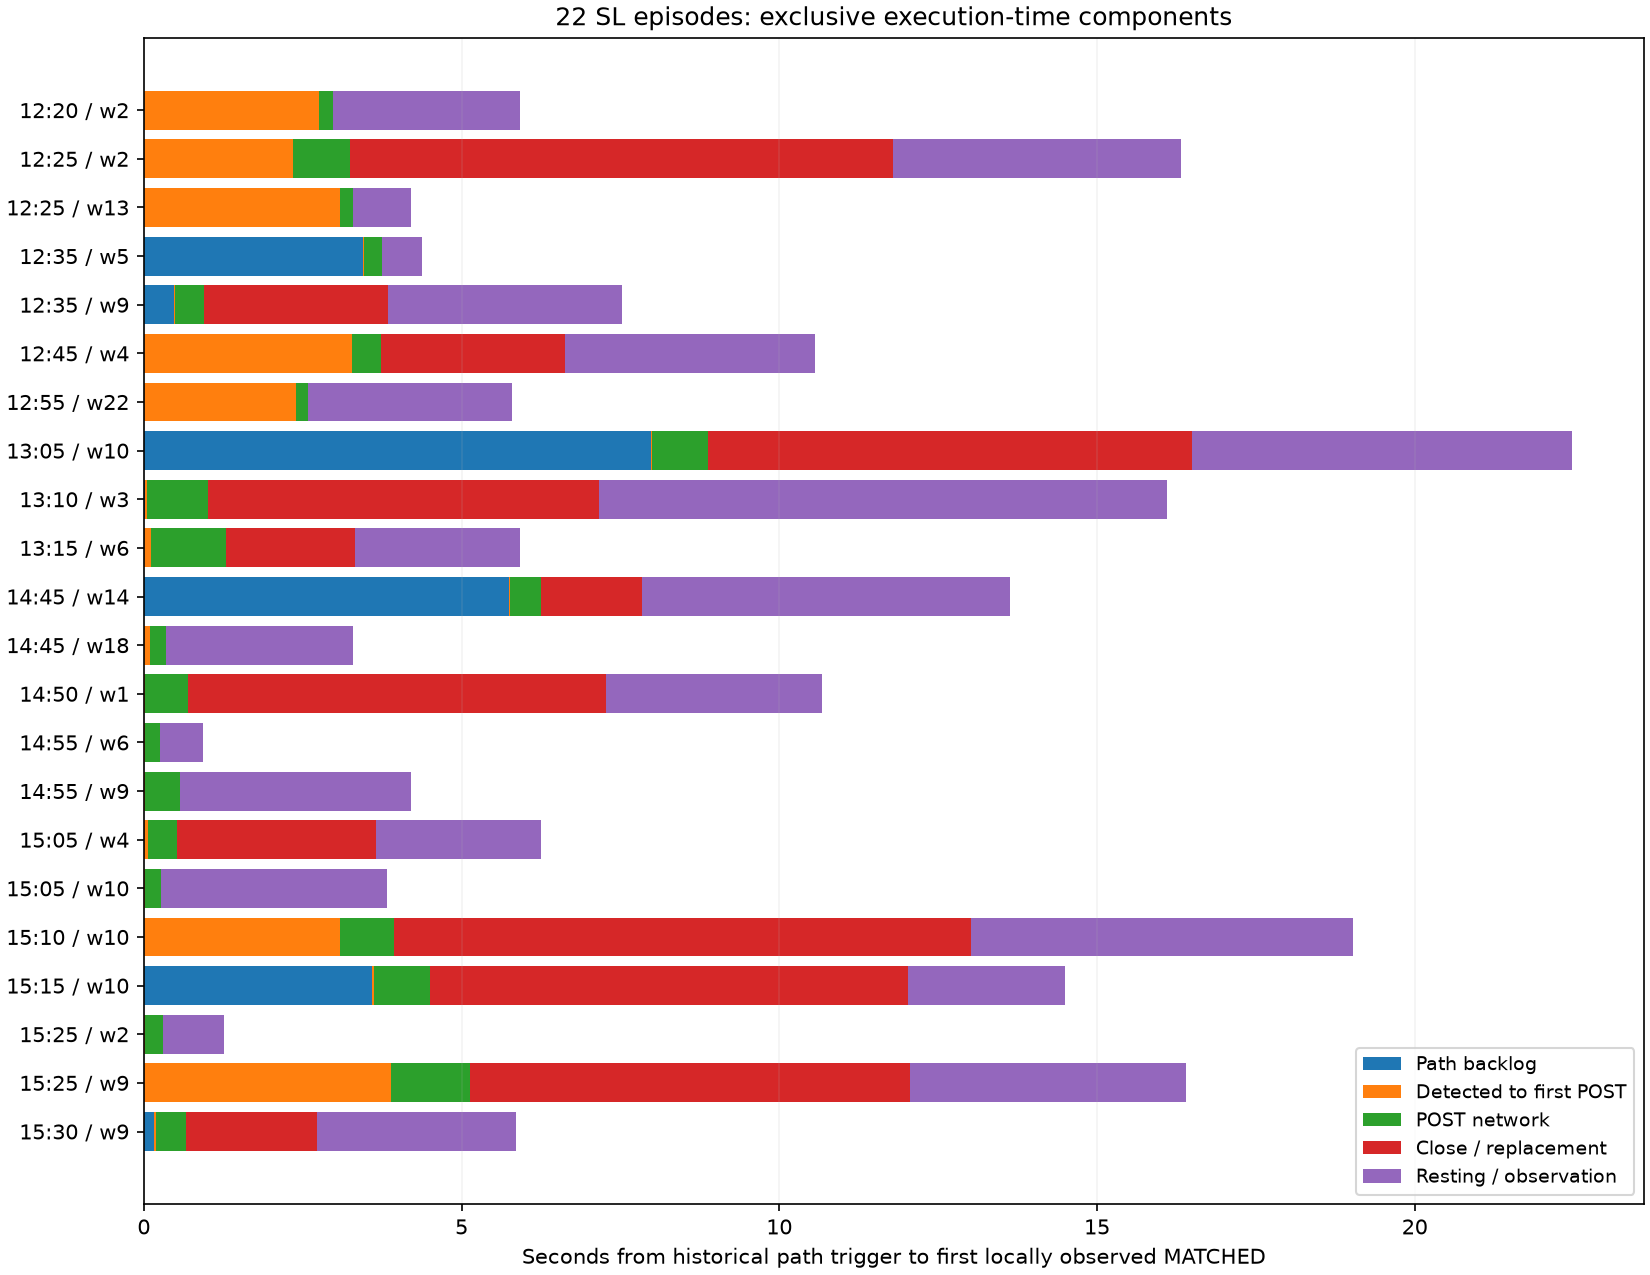

In [4]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
keys=list(eps[0]['time_phases']); names=['Path backlog','Detected to first POST','POST network','Close / replacement','Resting / observation']
fig,ax=plt.subplots(figsize=(11,8.5),layout='constrained'); left=np.zeros(len(eps)); y=np.arange(len(eps))
for key,label in zip(keys,names):
    values=np.array([e['time_phases'][key] for e in eps]);ax.barh(y,values,left=left,label=label);left+=values
ax.set_yticks(y,[e['market']+' / '+e['opening_window'].split(':')[-1] for e in eps]);ax.invert_yaxis()
ax.set(xlabel='Seconds from historical path trigger to first locally observed MATCHED',title='22 SL episodes: exclusive execution-time components')
ax.legend(loc='lower right',fontsize=9);ax.grid(axis='x',alpha=.15)
fig.savefig(OUT/'sl-time-components.png',dpi=150);plt.close(fig);display(Image(filename=str(OUT/'sl-time-components.png')))

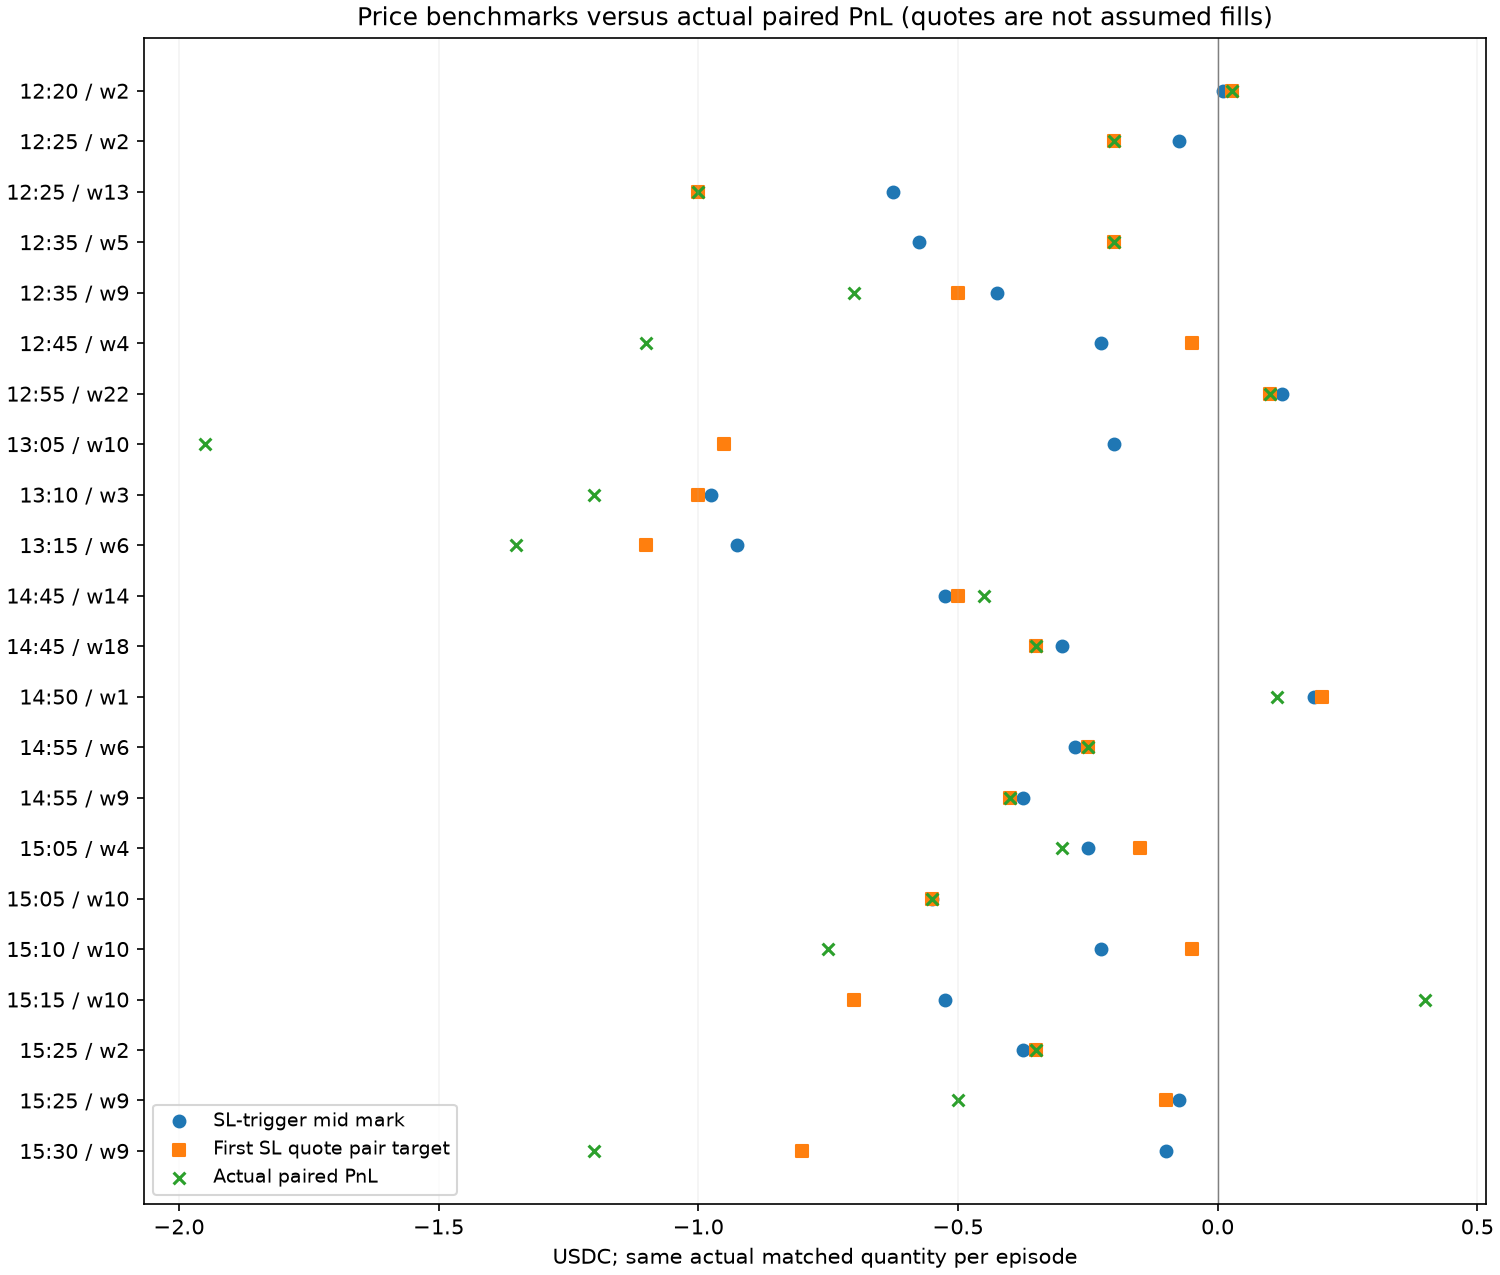

In [5]:
fig,ax=plt.subplots(figsize=(10,8.5),layout='constrained');y=np.arange(len(eps))
fields=['trigger_mark','first_post_quote_pair_target','actual_pair_pnl'];labels=['SL-trigger mid mark','First SL quote pair target','Actual paired PnL']
for key,label,marker in zip(fields,labels,['o','s','x']):
    ax.scatter([float(e['benchmarks'][key]) for e in eps],y,label=label,marker=marker,s=32)
ax.set_yticks(y,[e['market']+' / '+e['opening_window'].split(':')[-1] for e in eps]);ax.invert_yaxis()
ax.axvline(0,color='gray',linewidth=.7);ax.set(xlabel='USDC; same actual matched quantity per episode',title='Price benchmarks versus actual paired PnL (quotes are not assumed fills)')
ax.legend(loc='lower left',fontsize=9);ax.grid(axis='x',alpha=.15)
fig.savefig(OUT/'sl-pnl-benchmarks.png',dpi=150);plt.close(fig);display(Image(filename=str(OUT/'sl-pnl-benchmarks.png')))

## 解释

25次撤换中23个最终帧的公开页面最后完成项是positions/capital。22次零成交旧单的窄证据实际比下一POST平均早1.794秒。该段中点漂移净恶化1.35 USDC，不能假设提前Maker必成交。信号触发价到成交4.879675 USDC也是基准差额，不是可回收收益预测。例外包括等待期间改善的12:35及15:15，和15:05撤单请求后才观察到成交。

优先验证零成交撤换证据通路与重复DELETE水位；保持预算/Delta/未知成交保护。状态机参数和生产代码均未改动。完整时点、缓存read ID和源码位置见README.md及summary.json。